<img src="https://webna.ir/wp-content/uploads/2018/08/%D9%85%DA%A9%D8%AA%D8%A8-%D8%AE%D9%88%D9%86%D9%87.png" width=50% />

<div class="alert alert-block alert-success">
    <h1 align="center">Machine Learning in Python</h1>
    <h3 align="center">Mini Project2 - Bike Sharing</h3>
</div>

<img src = "https://storage.googleapis.com/kaggle-competitions/kaggle/3948/media/bikes.png" width=80%>

## Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

## Load and Prepare Data

In [3]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sample = pd.read_csv('sampleSubmission.csv')

print('Train shape:', train.shape)
print('Test shape:', test.shape)
print('Sample submission shape:', sample.shape)

Train shape: (10886, 12)
Test shape: (6493, 9)
Sample submission shape: (6493, 2)


In [4]:
train['datetime'] = pd.to_datetime(train['datetime'])
test['datetime'] = pd.to_datetime(test['datetime'])

In [5]:
# Extract time-based features from the datetime column.
for df in (train, test):
    df['year'] = df['datetime'].dt.year
    df['month'] = df['datetime'].dt.month
    df['day'] = df['datetime'].dt.day
    df['hour'] = df['datetime'].dt.hour
    df['weekday'] = df['datetime'].dt.weekday

train[['datetime', 'year', 'month', 'day', 'hour', 'weekday']].head()

,datetime,year,month,day,hour,weekday
0,2011-01-01 00:00:00,2011,1,1,0,5
1,2011-01-01 01:00:00,2011,1,1,1,5
2,2011-01-01 02:00:00,2011,1,1,2,5
3,2011-01-01 03:00:00,2011,1,1,3,5
4,2011-01-01 04:00:00,2011,1,1,4,5


## EDA

In [6]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   datetime    10886 non-null  datetime64[us]
 1   season      10886 non-null  int64         
 2   holiday     10886 non-null  int64         
 3   workingday  10886 non-null  int64         
 4   weather     10886 non-null  int64         
 5   temp        10886 non-null  float64       
 6   atemp       10886 non-null  float64       
 7   humidity    10886 non-null  int64         
 8   windspeed   10886 non-null  float64       
 9   casual      10886 non-null  int64         
 10  registered  10886 non-null  int64         
 11  count       10886 non-null  int64         
 12  year        10886 non-null  int32         
 13  month       10886 non-null  int32         
 14  day         10886 non-null  int32         
 15  hour        10886 non-null  int32         
 16  weekday     10886 non-null  int32

In [7]:
train.describe()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour,weekday
count,10886,10886.000000,10886.000000,10886.000000,10886.000000,10886.00000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000,10886.000000
mean,2011-12-27 05:56:22.399412,2.506614,0.028569,0.680875,1.418427,20.23086,23.655084,61.886460,12.799395,36.021955,155.552177,191.574132,2011.501929,6.521495,9.992559,11.541613,3.013963
min,2011-01-01 00:00:00,1.000000,0.000000,0.000000,1.000000,0.82000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000,2011.000000,1.000000,1.000000,0.000000,0.000000
25%,2011-07-02 07:15:00,2.000000,0.000000,0.000000,1.000000,13.94000,16.665000,47.000000,7.001500,4.000000,36.000000,42.000000,2011.000000,4.000000,5.000000,6.000000,1.000000
50%,2012-01-01 20:30:00,3.000000,0.000000,1.000000,1.000000,20.50000,24.240000,62.000000,12.998000,17.000000,118.000000,145.000000,2012.000000,7.000000,10.000000,12.000000,3.000000
75%,2012-07-01 12:45:00,4.000000,0.000000,1.000000,2.000000,26.24000,31.060000,77.000000,16.997900,49.000000,222.000000,284.000000,2012.000000,10.000000,15.000000,18.000000,5.000000
max,2012-12-19 23:00:00,4.000000,1.000000,1.000000,4.000000,41.00000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000,2012.000000,12.000000,19.000000,23.000000,6.000000
std,NaN,1.116174,0.166599,0.466159,0.633839,7.79159,8.474601,19.245033,8.164537,49.960477,151.039033,181.144454,0.500019,3.444373,5.476608,6.915838,2.004585


In [8]:
print('Missing values in train:')
print(train.isnull().sum())

print('\nMissing values in test:')
print(test.isnull().sum())

Missing values in train:
datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
year          0
month         0
day           0
hour          0
weekday       0
dtype: int64

Missing values in test:
datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
year          0
month         0
day           0
hour          0
weekday       0
dtype: int64


In [9]:
train.groupby('season')['count'].mean().sort_values(ascending=False)

season
3    234.417124
2    215.251372
4    198.988296
1    116.343261
Name: count, dtype: float64

In [10]:
train.groupby('hour')['count'].mean().sort_values(ascending=False)

hour
17    468.765351
18    430.859649
8     362.769231
16    316.372807
19    315.278509
13    257.787281
12    256.508772
15    254.298246
14    243.442982
20    228.517544
9     221.780220
7     213.116484
11    210.674725
10    175.092308
21    173.370614
22    133.576754
23     89.508772
6      76.259341
0      55.138462
1      33.859031
2      22.899554
5      19.767699
3      11.757506
4       6.407240
Name: count, dtype: float64

In [11]:
numeric_train = train.select_dtypes(include=[np.number])
numeric_train.corr()['count'].sort_values(ascending=False)

count         1.000000
registered    0.970948
casual        0.690414
hour          0.400601
temp          0.394454
atemp         0.389784
year          0.260403
month         0.166862
season        0.163439
windspeed     0.101369
day           0.019826
workingday    0.011594
weekday      -0.002283
holiday      -0.005393
weather      -0.128655
humidity     -0.317371
Name: count, dtype: float64

## Data Preprocessing

In [12]:
# Add cyclic encodings so nearby hours and months have nearby representations.
for df in (train, test):
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

In [13]:
# Exclude target components and datetime from the model features.
feature_columns = [
    column for column in train.columns
    if column not in ['datetime', 'casual', 'registered', 'count']
]

X = train[feature_columns]
y = train['count']
X_test = test[feature_columns]

print('Number of features:', len(feature_columns))
print(feature_columns)

Number of features: 17
['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'year', 'month', 'day', 'hour', 'weekday', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


In [14]:
# Split before fitting any scaler to avoid data leakage.
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Training rows:', X_train.shape[0])
print('Validation rows:', X_val.shape[0])

Training rows: 8708
Validation rows: 2178


In [15]:
# Fit the scaler on the training split only.
# Random Forest does not need scaled features; scaled data is used only for scale-sensitive models.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

## Strorytelling - Visualization

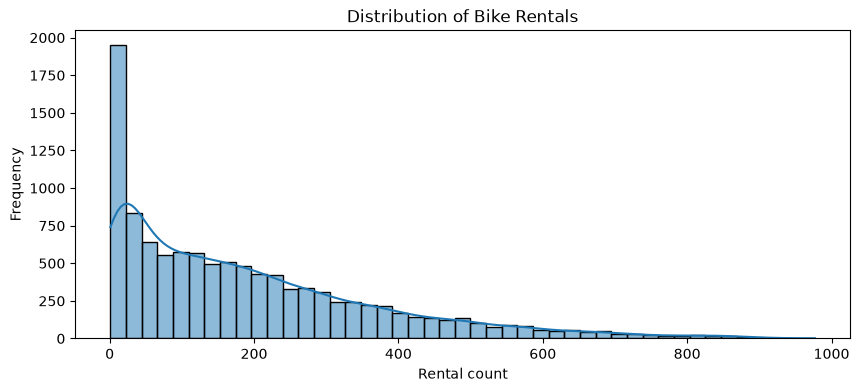

In [16]:
plt.figure(figsize=(10, 4))
sns.histplot(train['count'], kde=True)
plt.title('Distribution of Bike Rentals')
plt.xlabel('Rental count')
plt.ylabel('Frequency')
plt.show()

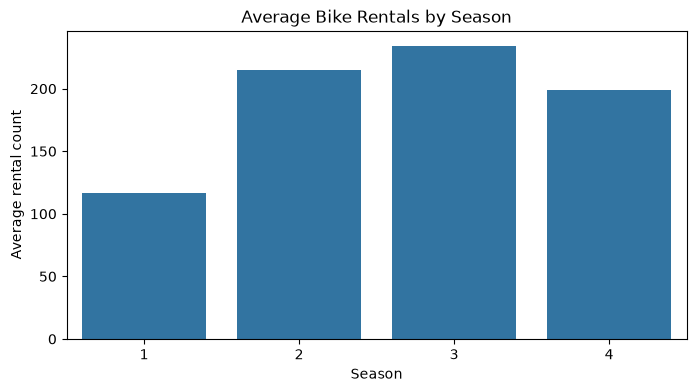

In [17]:
plt.figure(figsize=(8, 4))
sns.barplot(data=train, x='season', y='count', errorbar=None)
plt.title('Average Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Average rental count')
plt.show()

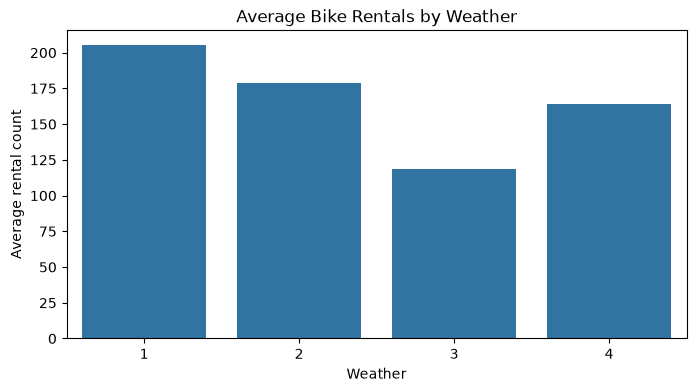

In [18]:
plt.figure(figsize=(8, 4))
sns.barplot(data=train, x='weather', y='count', errorbar=None)
plt.title('Average Bike Rentals by Weather')
plt.xlabel('Weather')
plt.ylabel('Average rental count')
plt.show()

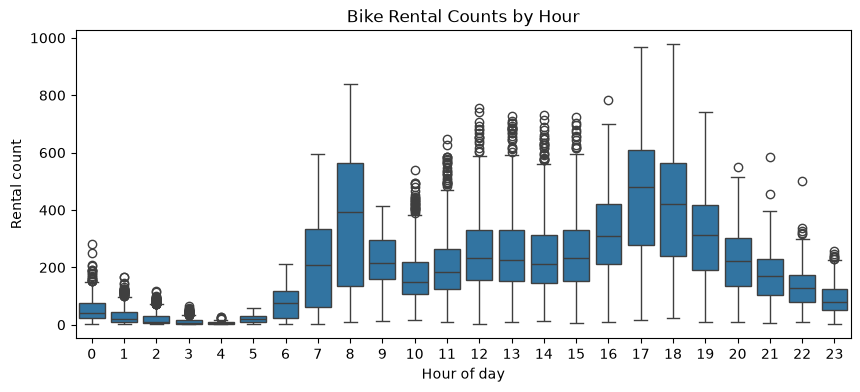

In [19]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=train, x='hour', y='count')
plt.title('Bike Rental Counts by Hour')
plt.xlabel('Hour of day')
plt.ylabel('Rental count')
plt.show()

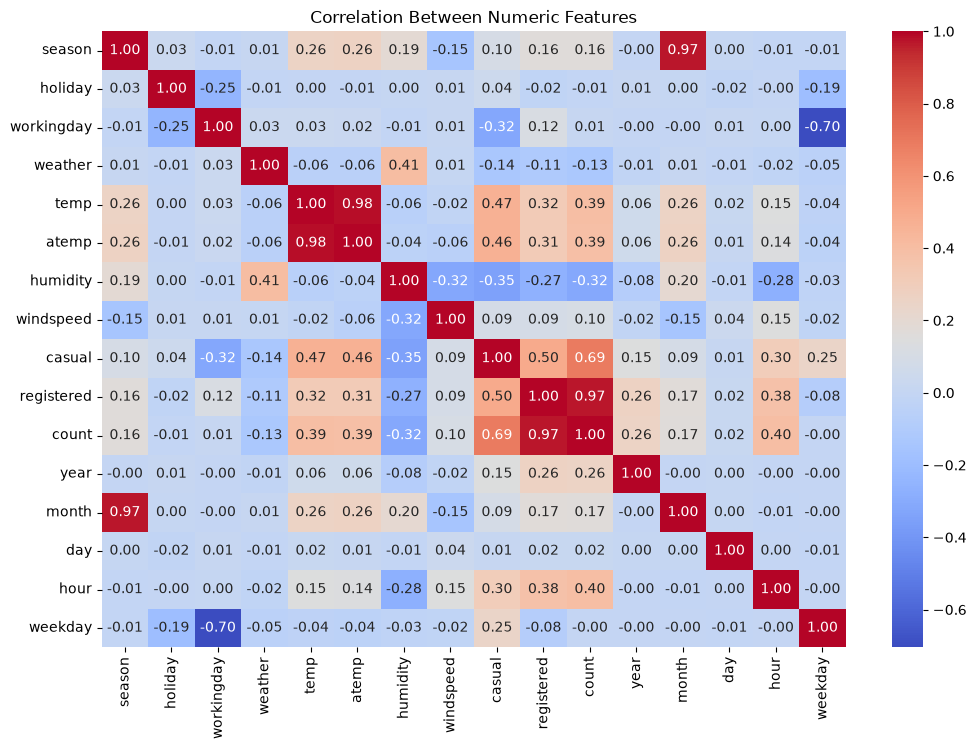

In [20]:
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_train.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Between Numeric Features')
plt.show()

## Train your model (Regression)

In [21]:
# Compare scale-sensitive models using scaled data and tree models using the original features.
models = {
    'Linear Regression': (LinearRegression(), X_train_scaled, X_val_scaled),
    'KNN Regressor': (KNeighborsRegressor(n_neighbors=5), X_train_scaled, X_val_scaled),
    'Decision Tree': (DecisionTreeRegressor(random_state=42), X_train, X_val),
    'Random Forest': (
        RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        X_train,
        X_val
    )
}

validation_results = {}

for name, (model, train_features, validation_features) in models.items():
    model.fit(train_features, y_train)
    predictions = model.predict(validation_features)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    validation_results[name] = rmse
    print(f'{name}: validation RMSE = {rmse:.4f}')

Linear Regression: validation RMSE = 125.6603
KNN Regressor: validation RMSE = 90.0984
Decision Tree: validation RMSE = 54.0917
Random Forest: validation RMSE = 38.7298


In [22]:
# Use Random Forest for the final model; it does not require feature scaling.
rf_model = models['Random Forest'][0]
validation_predictions = np.clip(rf_model.predict(X_val), 0, None)

validation_rmse = np.sqrt(mean_squared_error(y_val, validation_predictions))
validation_r2 = r2_score(y_val, validation_predictions)

print(f'Random Forest validation RMSE: {validation_rmse:.4f}')
print(f'Random Forest validation R-squared: {validation_r2:.4f}')

Random Forest validation RMSE: 38.7298
Random Forest validation R-squared: 0.9546


## Test Result

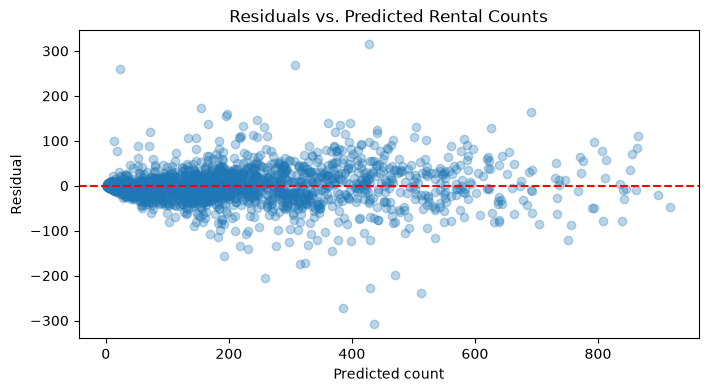

In [23]:
# Inspect residuals on the held-out validation split.
residuals = y_val - validation_predictions

plt.figure(figsize=(8, 4))
plt.scatter(validation_predictions, residuals, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs. Predicted Rental Counts')
plt.xlabel('Predicted count')
plt.ylabel('Residual')
plt.show()

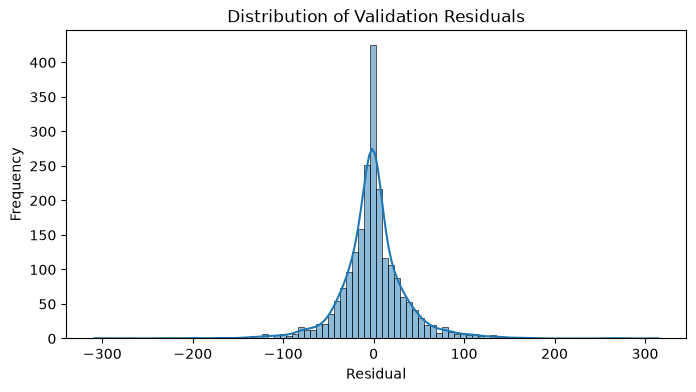

In [24]:
plt.figure(figsize=(8, 4))
sns.histplot(residuals, kde=True)
plt.title('Distribution of Validation Residuals')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.show()

hour          0.379402
hour_sin      0.140871
year          0.087642
workingday    0.069448
hour_cos      0.065433
temp          0.058787
month         0.050267
atemp         0.035677
weekday       0.032465
humidity      0.026547
weather       0.014886
season        0.010124
day           0.009609
month_sin     0.007234
windspeed     0.007193
month_cos     0.003223
holiday       0.001191
dtype: float64


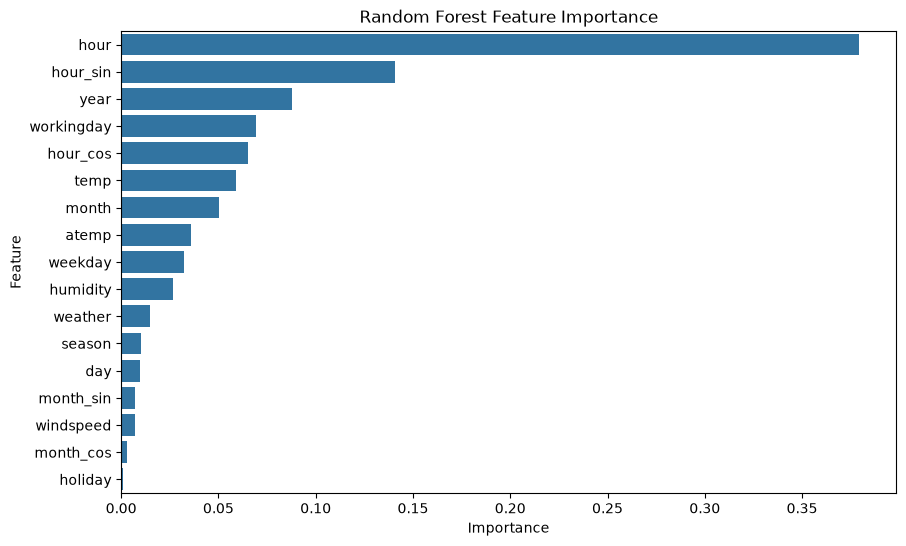

In [25]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_columns
).sort_values(ascending=False)

print(feature_importance)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importance.values, y=feature_importance.index)
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [26]:
# Refit the selected model on all labeled training data before predicting test rows.
final_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
final_model.fit(X, y)

test_predictions = np.clip(final_model.predict(X_test), 0, None)

In [27]:
# Preserve the sample submission's datetime order and replace only the target column.
submission = sample.copy()
submission['count'] = test_predictions

assert submission.shape == sample.shape
assert submission['datetime'].equals(sample['datetime'])
assert submission['count'].notnull().all()
assert (submission['count'] >= 0).all()

submission.to_csv('my_submission.csv', index=False)

# Read the file back and validate its structure and values.
saved_submission = pd.read_csv('my_submission.csv')
assert saved_submission.shape == sample.shape
assert saved_submission['datetime'].equals(sample['datetime'])
assert saved_submission['count'].notnull().all()
assert (saved_submission['count'] >= 0).all()

print(saved_submission.head())
print('Validated submission shape:', saved_submission.shape)
print('Saved as my_submission.csv')

              datetime  count
0  2011-01-20 00:00:00  13.37
1  2011-01-20 01:00:00   6.85
2  2011-01-20 02:00:00   6.88
3  2011-01-20 03:00:00   3.88
4  2011-01-20 04:00:00   3.03
Validated submission shape: (6493, 2)
Saved as my_submission.csv


## Send us the Result (Maktabkhoone)